Loading and inspecting the dataset

In [ ]:

import pandas as pd
import numpy as np

df = pd.read_csv("college_iot_energy_monitoring.csv")

print("Dataset shape:", df.shape)
print("\nFirst 5 records:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())


Dataset shape: (2000, 8)

First 5 records:


,device,hour,day,temperature,humidity,power,duration,energy
0,Agriculture Block - Irrigation System Load,9,29,22.27,39.65,2115.406021,4.1982,0.104992
1,Agriculture Block - Crop Monitoring Load,21,20,30.03,40.42,569.237511,5.4644,0.134754
2,Agriculture Block - Greenhouse Lighting Load,6,3,29.24,61.64,2990.349781,1.3133,0.028226
3,Mechanical Block - CNC Machine Load,8,19,22.10,95.00,28833.701030,2.1353,0.116440
4,Agriculture Block - Irrigation System Load,16,22,21.82,38.87,2051.381944,1.4630,0.025927



Data types:
device          object
hour             int64
day              int64
temperature    float64
humidity       float64
power          float64
duration       float64
energy         float64
dtype: object

Missing values:
device         0
hour           0
day            0
temperature    0
humidity       0
power          0
duration       0
energy         0
dtype: int64

Duplicate rows: 0

Statistical summary:


,hour,day,temperature,humidity,power,duration,energy
count,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,11.60650,16.505000,26.703965,51.136165,8403.469271,3.233710,0.121617
std,7.00144,8.844099,4.059669,9.771803,11345.900507,2.235076,0.073677
min,0.00000,1.000000,4.000000,2.000000,97.097051,0.093000,0.005000
25%,5.00000,9.000000,22.400000,40.827500,1406.113117,1.412000,0.074274
50%,12.00000,17.000000,28.195000,53.845000,2031.386672,2.733800,0.115929
75%,18.00000,24.000000,29.960000,59.802500,12803.278655,4.941925,0.162659
max,23.00000,31.000000,54.000000,99.000000,47219.502186,8.000000,0.933048


Data Validation

In [ ]:


print("Hour outside 0-23:", (~df["hour"].between(0, 23)).sum())
print("Day outside 1-31:", (~df["day"].between(1, 31)).sum())

for col in ["temperature", "humidity", "power",
            "duration", "energy"]:
    print(f"{col}:")
    print("  Negative values:", (df[col] < 0).sum())
    print("  Minimum:", df[col].min())
    print("  Maximum:", df[col].max())

calculated_energy = df["power"] * df["duration"] / 1000

print(
    "\nMaximum difference between recorded and "
    "calculated energy:",
    (df["energy"] - calculated_energy).abs().max()
)


Hour outside 0-23: 0
Day outside 1-31: 0
temperature:
  Negative values: 0
  Minimum: 4.0
  Maximum: 54.0
humidity:
  Negative values: 0
  Minimum: 2.0
  Maximum: 99.0
power:
  Negative values: 0
  Minimum: 97.09705077380652
  Maximum: 47219.502186
duration:
  Negative values: 0
  Minimum: 0.093
  Maximum: 8.0
energy:
  Negative values: 0
  Minimum: 0.005
  Maximum: 0.933048

Maximum difference between recorded and calculated energy: 268.0369377111797


Device Distribution

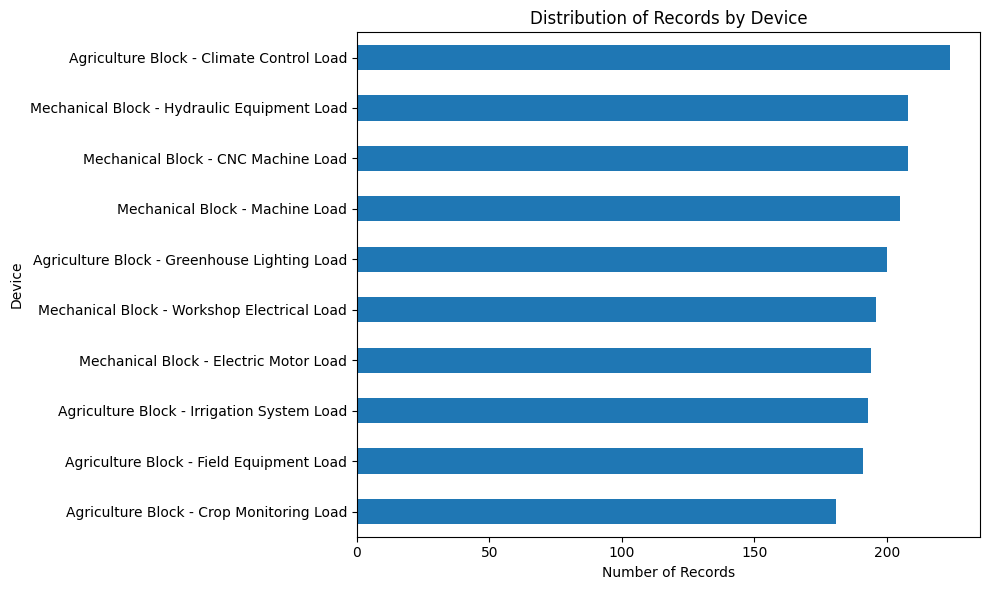

,record_count
device,
Agriculture Block - Climate Control Load,224
Mechanical Block - CNC Machine Load,208
Mechanical Block - Hydraulic Equipment Load,208
Mechanical Block - Machine Load,205
Agriculture Block - Greenhouse Lighting Load,200
Mechanical Block - Workshop Electrical Load,196
Mechanical Block - Electric Motor Load,194
Agriculture Block - Irrigation System Load,193
Agriculture Block - Field Equipment Load,191


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

device_counts = df["device"].value_counts().sort_values()

plt.figure(figsize=(10, 6))
device_counts.plot(kind="barh")

plt.xlabel("Number of Records")
plt.ylabel("Device")
plt.title("Distribution of Records by Device")
plt.tight_layout()
plt.show()

display(
    device_counts.sort_values(ascending=False)
    .rename("record_count")
    .to_frame()
)


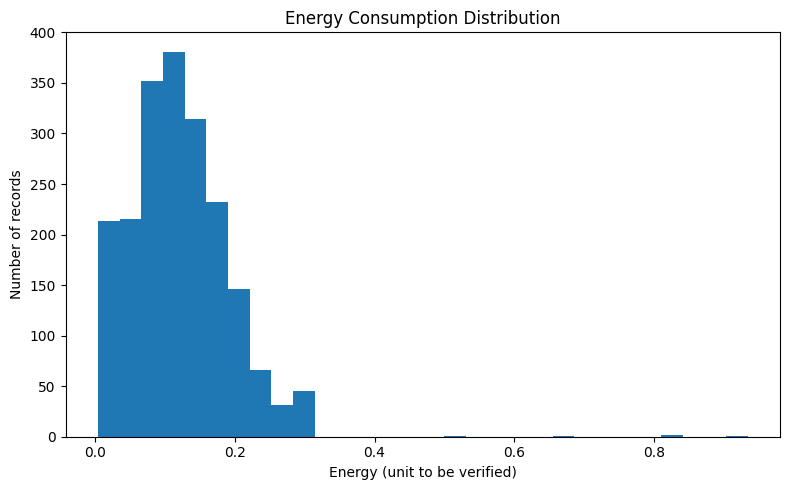

In [ ]:
import matplotlib.pyplot as plt
# Distribution of energy consumption
plt.figure(figsize=(8, 5))
plt.hist(df["energy"], bins=30)
plt.xlabel("Energy (unit to be verified)")
plt.ylabel("Number of records")
plt.title("Energy Consumption Distribution")
plt.tight_layout()
plt.show()

# Average energy by hour
hourly_energy = df.groupby("hour")["energy"].mean()



comparision between two blocks

,records,average_energy,total_energy,average_power
block,,,,
Agriculture Block,989,0.108162,106.972487,1562.345918
Mechanical Block,1011,0.134779,136.261979,15095.725449


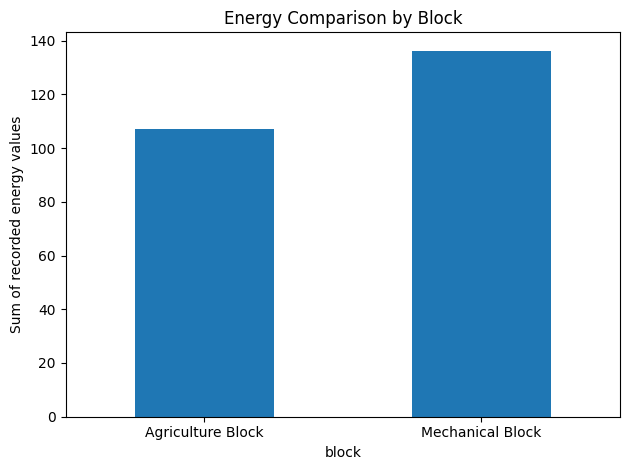

In [ ]:

df["block"] = np.where(
    df["device"].str.startswith("Agriculture Block"),
    "Agriculture Block",
    "Mechanical Block"
)

summary = df.groupby("block").agg(
    records=("energy", "size"),
    average_energy=("energy", "mean"),
    total_energy=("energy", "sum"),
    average_power=("power", "mean")
)

display(summary)

summary["total_energy"].plot(kind="bar")
plt.ylabel("Sum of recorded energy values")
plt.title("Energy Comparison by Block")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


distribution energy over time

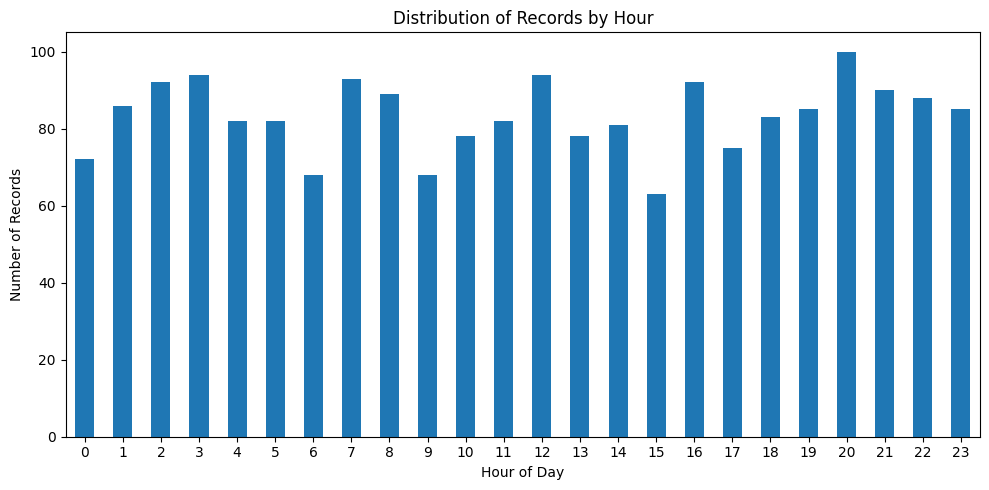

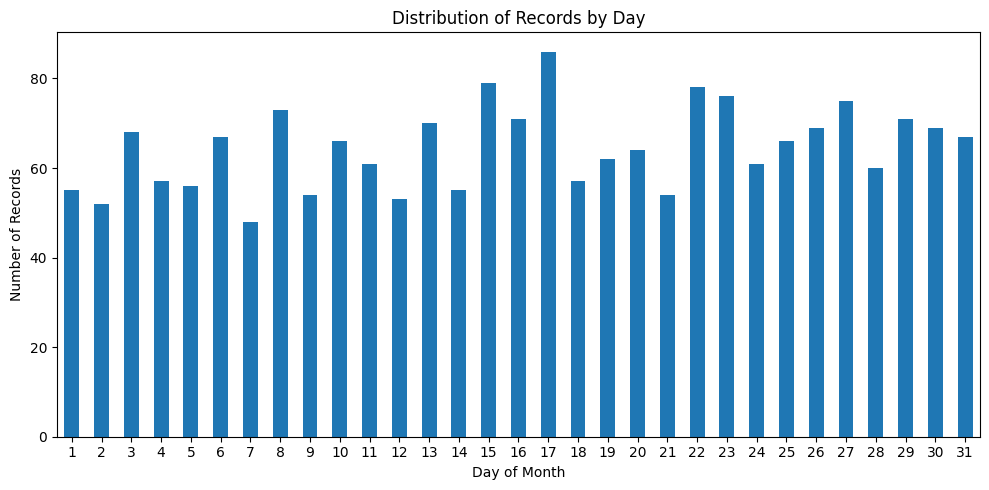

In [ ]:

import matplotlib.pyplot as plt

# 1. Number of records by hour
plt.figure(figsize=(10, 5))
df["hour"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Records")
plt.title("Distribution of Records by Hour")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Number of records by day
plt.figure(figsize=(10, 5))
df["day"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Day of Month")
plt.ylabel("Number of Records")
plt.title("Distribution of Records by Day")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Time-Based Energy Trends Analysis

Let's analyze how energy consumption varies across different hours of the day and different days of the month.

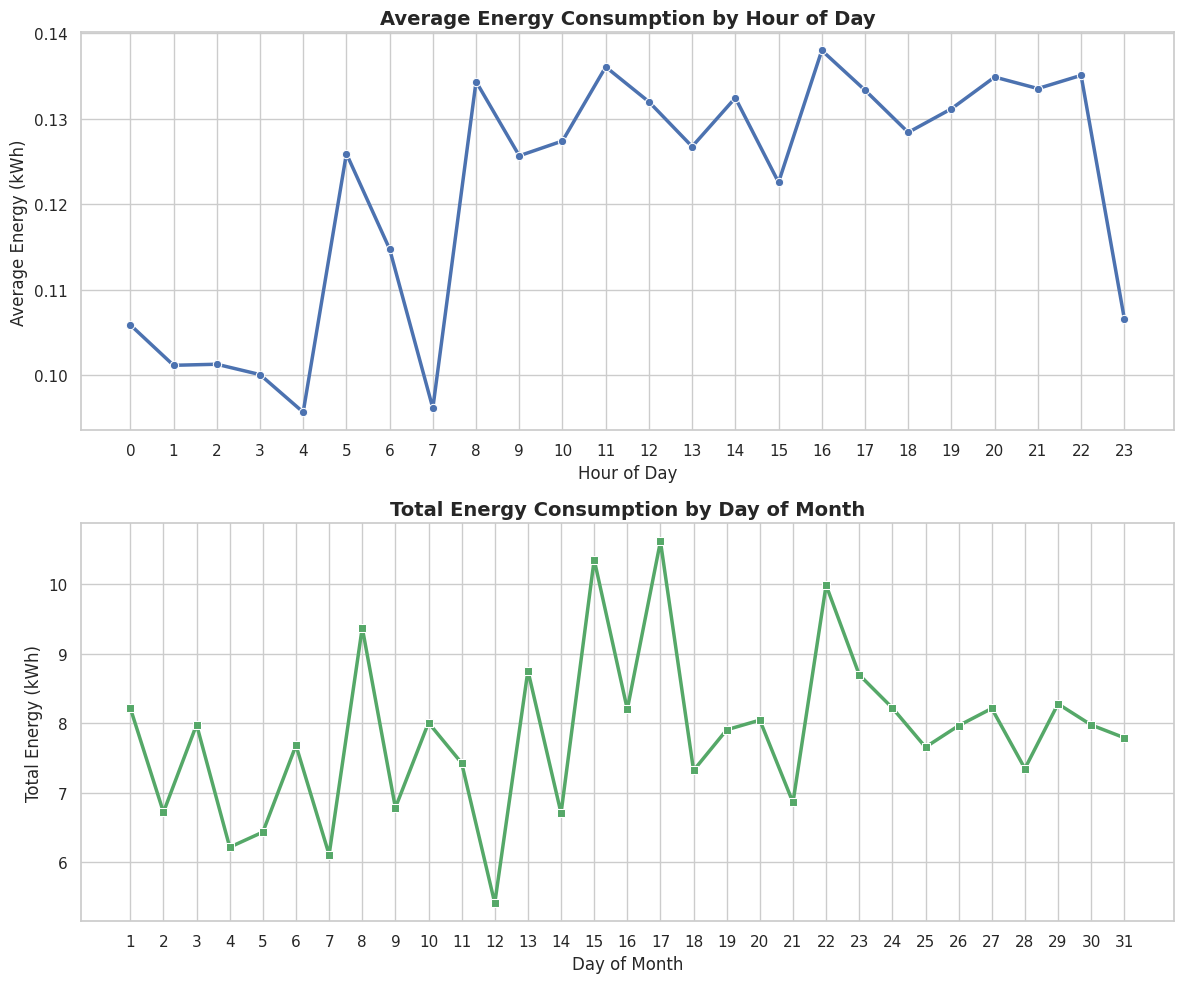

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure styling
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# 1. Hourly Average Energy Trend
hourly_avg_energy = df.groupby("hour")["energy"].mean().reset_index()
sns.lineplot(ax=axes[0], data=hourly_avg_energy, x="hour", y="energy", marker="o", color="b", linewidth=2.5)
axes[0].set_title("Average Energy Consumption by Hour of Day", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Hour of Day", fontsize=12)
axes[0].set_ylabel("Average Energy (kWh)", fontsize=12)
axes[0].set_xticks(range(0, 24))

# 2. Daily Total Energy Trend
daily_total_energy = df.groupby("day")["energy"].sum().reset_index()
sns.lineplot(ax=axes[1], data=daily_total_energy, x="day", y="energy", marker="s", color="g", linewidth=2.5)
axes[1].set_title("Total Energy Consumption by Day of Month", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Day of Month", fontsize=12)
axes[1].set_ylabel("Total Energy (kWh)", fontsize=12)
axes[1].set_xticks(range(1, 32))

plt.tight_layout()
plt.show()

---distributions of all features---

Dataset shape: (2000, 8)

Columns: ['device', 'hour', 'day', 'temperature', 'humidity', 'power', 'duration', 'energy']

Data types:
 device          object
hour             int64
day              int64
temperature    float64
humidity       float64
power          float64
duration       float64
energy         float64
dtype: object


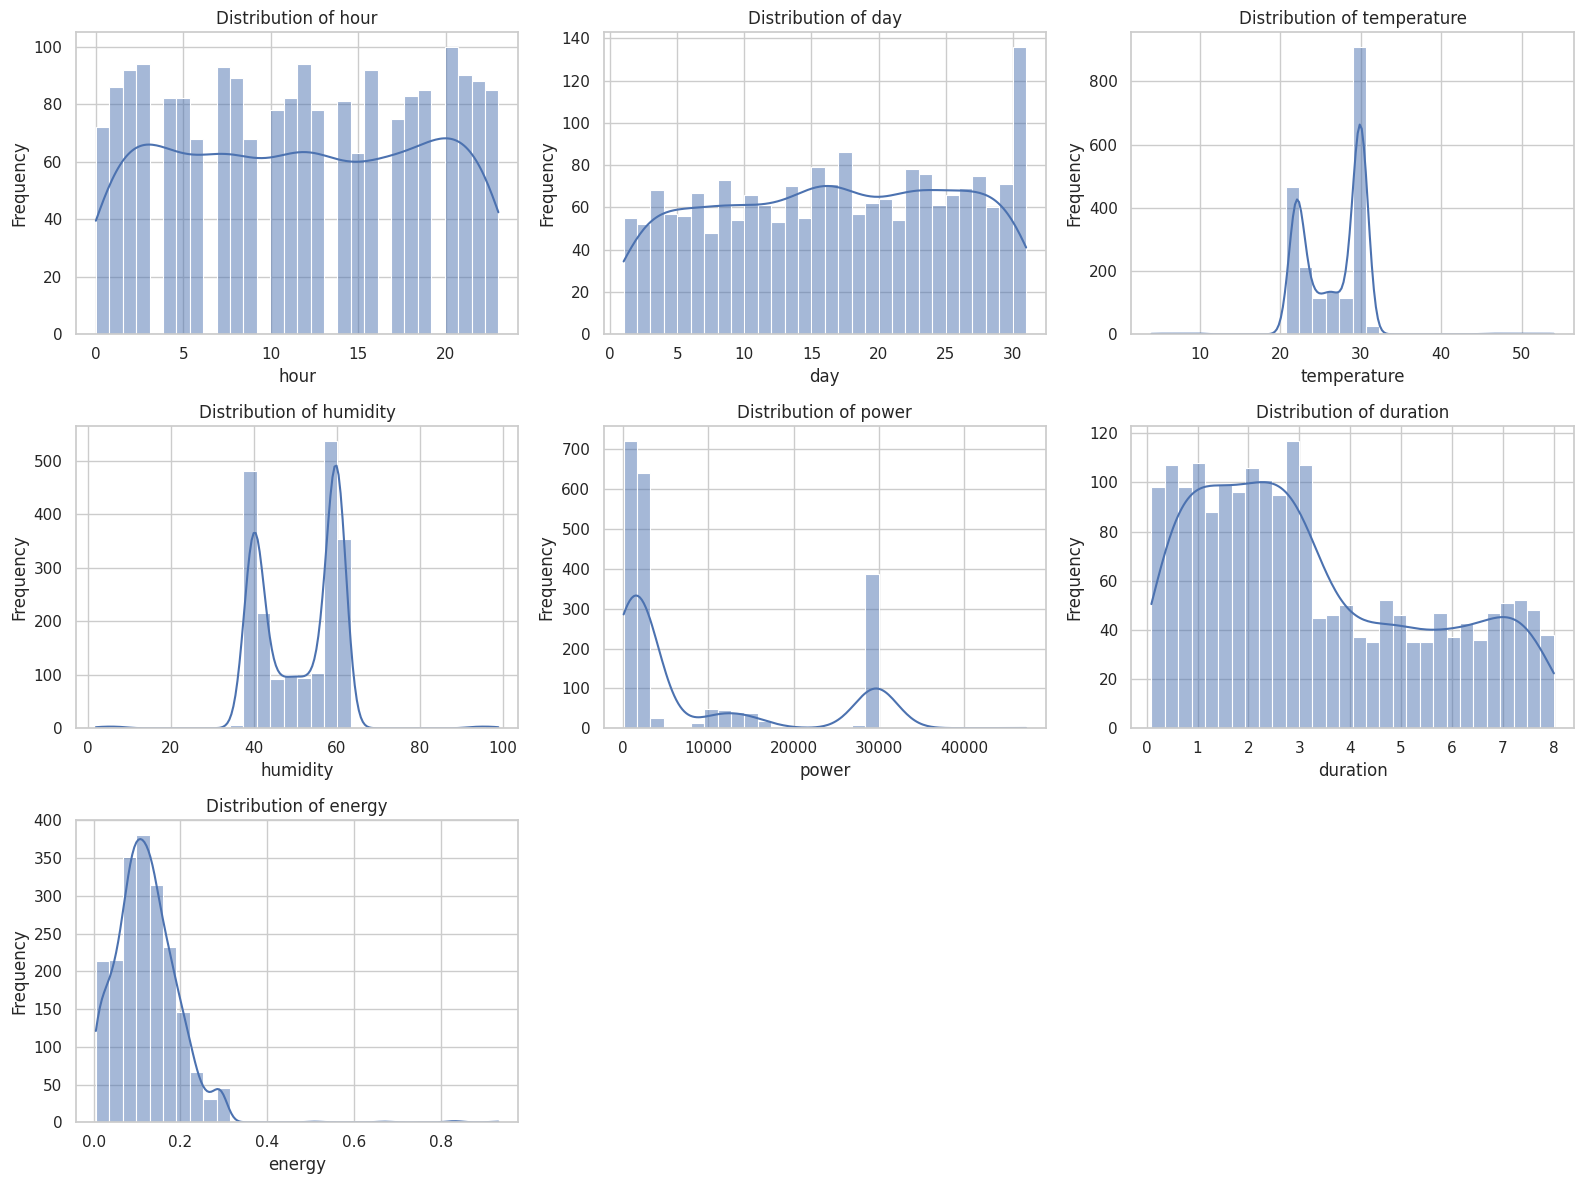

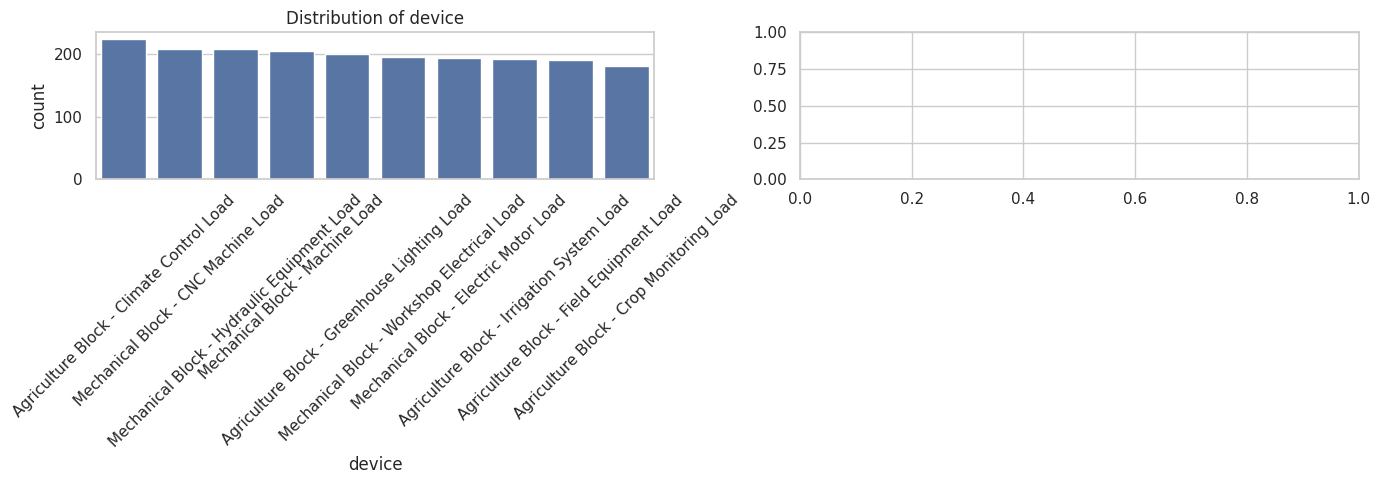

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Load dataset
df = pd.read_csv(
    "college_iot_energy_monitoring.csv"
)

# Display dataset information
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:\n", df.dtypes)

# Separate numerical and categorical features
numerical_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

sns.set_theme(style="whitegrid")

# Plot numerical feature distributions
n_cols = 3
n_rows = math.ceil(len(numerical_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(16, 4 * n_rows)
)
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[i],
        bins=30
    )
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

# Hide unused subplots
for j in range(len(numerical_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# Plot categorical feature distributions
if categorical_cols:
    n_cols = 2
    n_rows = math.ceil(len(categorical_cols) / n_cols)

    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(14, 5 * n_rows)
    )
    axes = axes.flatten()
    axes = axes if len(categorical_cols) > 1 else [axes[0]]

    for i, col in enumerate(categorical_cols):
        order = df[col].value_counts().index
        sns.countplot(
            data=df,
            x=col,
            order=order,
            ax=axes[i]
        )
        axes[i].set_title(f"Distribution of {col}")
        axes[i].tick_params(axis="x", rotation=45)

    for j in range(len(categorical_cols), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()
